# Exploración del dataset

Recorrido básico del CSV sintético de SOFLEX. El archivo original está en `data/raw/`. Este notebook solo llama funciones de los scripts; no modifica datos ni evalúa modelos.

Ejecutar las celdas en orden. El kernel puede iniciarse en `notebooks/` o en la raíz del repo. Dependencias opcionales: `requirements-notebook.txt` (en esta carpeta).

In [1]:
import sys
from pathlib import Path

# Permite abrirlo con el kernel en notebooks/ o en la raíz del repo.
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import pandas as pd
from IPython.display import display

from scripts.audit_dataset import DEFAULT_DATASET, audit_dataset
from scripts.explore_dataset import (
    preview_dataset, dataset_overview, plot_distribution,
    findings_overview, findings_for, record_detail,
)

pd.set_option('display.max_colwidth', None)
report = audit_dataset(DEFAULT_DATASET)

## Primeras filas

La transcripción es la entrada principal. Las otras columnas incluyen etiquetas y referencias: no deben pasarse al extractor como si fueran parte del relato.

In [2]:
display(preview_dataset())

,id_registro,categoria,prioridad_sugerida,calle_detectada,altura_detectada
0,SFX-REC-2026-001,INCENDIO_RESCATE,P1,Av. Corrientes,1540
1,SFX-REC-2026-002,INCENDIO_RESCATE,P3,Av. Raúl Scalabrini Ortiz,800
2,SFX-REC-2026-003,INCENDIO_RESCATE,P2,Billinghurst,1845
3,SFX-REC-2026-004,INCENDIO_RESCATE,P2,Av. Castañares,4500 (esquina)
4,SFX-REC-2026-005,ACCIDENTE_VIAL,P1,Av. San Juan,1800 (esquina)


## Estructura y cobertura

No hay celdas vacías ni duplicados detectados. Cada subcategoría tiene una sola muestra: la variedad de etiquetas no implica cobertura suficiente.

In [3]:
display(dataset_overview(report))

,Indicador,Cantidad
0,Registros,30
1,Columnas,18
2,IDs únicos,30
3,Relatos únicos,30
4,Celdas vacías,0
5,Subcategorías,30
6,Errores detectados,0


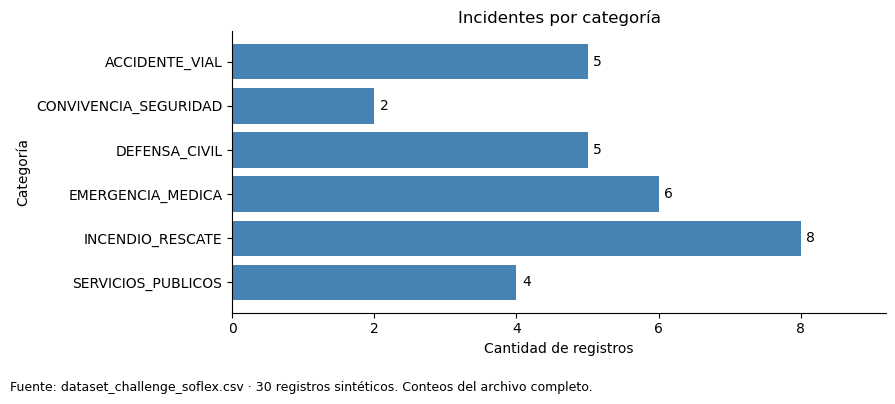

In [4]:
plot_distribution(report, 'categoria', 'Incidentes por categoría')

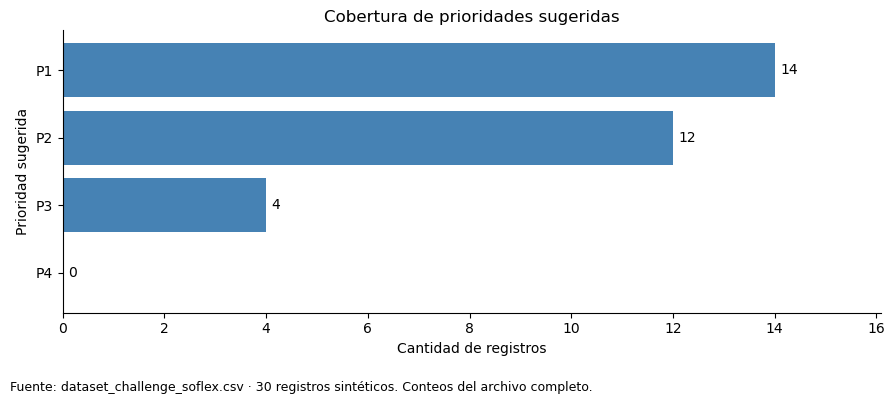

In [5]:
plot_distribution(report, 'prioridad_sugerida', 'Cobertura de prioridades sugeridas')

P4 no tiene ejemplos. Los gráficos cuentan los registros originales; no muestran resultados de un modelo.

## Señales para revisar

Son comparaciones literales, no errores semánticos confirmados. Una fila puede tener varias señales. La normalización de nombres de calles o el enriquecimiento de comuna también puede producirlas.

In [6]:
display(findings_overview(report))

,Señal de revisión o error,Cantidad
0,checklist_not_literal_partition,30
1,height_not_literal,9
2,intersection_part_not_literal,34
3,location_not_literal,39
4,non_simple_height,12


### Alturas que no aparecen literalmente

La altura de referencia puede venir de información externa. No debería exigirse al extractor que la invente.

In [7]:
display(findings_for(report, 'height_not_literal'))

,record,field,detail,severity,code
0,SFX-REC-2026-004,altura_detectada,La altura 4500 no aparece como token en el relato.,review,height_not_literal
1,SFX-REC-2026-005,altura_detectada,La altura 1800 no aparece como token en el relato.,review,height_not_literal
2,SFX-REC-2026-007,altura_detectada,La altura 3100 no aparece como token en el relato.,review,height_not_literal
3,SFX-REC-2026-013,altura_detectada,La altura 4200 no aparece como token en el relato.,review,height_not_literal
4,SFX-REC-2026-015,altura_detectada,La altura 1500 no aparece como token en el relato.,review,height_not_literal
5,SFX-REC-2026-016,altura_detectada,La altura 3900 no aparece como token en el relato.,review,height_not_literal
6,SFX-REC-2026-018,altura_detectada,La altura 1100 no aparece como token en el relato.,review,height_not_literal
7,SFX-REC-2026-021,altura_detectada,La altura 3400 no aparece como token en el relato.,review,height_not_literal
8,SFX-REC-2026-024,altura_detectada,La altura 3600 no aparece como token en el relato.,review,height_not_literal


### Dos ejemplos concretos

El caso 001 agrega Paraná aunque el relato menciona Montevideo. Sus preguntas pendientes tampoco completan las obligatorias. El caso 018 agrega altura 1100 y Honduras a un relato que solo ubica Billinghurst y Gorriti.

In [8]:
display(record_detail('SFX-REC-2026-001'))

,SFX-REC-2026-001
transcripcion_cruda,"Operador: 911 emergencias, ¿dónde es su urgencia? Llamante: Hola, por favor manden a los bomberos ya! En la pizzería de Av. Corrientes 1540 casi Montevideo, se prendió fuego la campana de la cocina y se está metiendo el humo negro al salón, la gente salió corriendo a la calle pero adentro quedó el cocinero!"
calle_detectada,Av. Corrientes
altura_detectada,1540
interseccion_detectada,Montevideo y Paraná
preguntas_protocolo_mandatorias,¿Hay personas atrapadas en el interior? | ¿Hay garrafas o cañería de gas activa? | ¿Hay inmuebles linderos afectados?
preguntas_respondidas_en_relato,"¿Hay personas atrapadas en el interior? (Sí, el cocinero quedó adentro)"
preguntas_pendientes,¿Pudo cortar la llave de gas general? | ¿El humo afecta a los pisos superiores del edificio?


In [9]:
display(record_detail('SFX-REC-2026-018'))

,SFX-REC-2026-018
transcripcion_cruda,"Operador: 911, ¿dónde ocurre el hecho? Llamante: En la ciclovía de Billinghurst y Gorriti. Un colectivo dobló sin mirar y tiró al piso a un chico en monopatín o bicicleta. El chico quedó debajo del estribo, está consciente pero no puede mover la pierna derecha y el colectivo frenó de golpe atravesado en la calle."
calle_detectada,Billinghurst
altura_detectada,1100 (esquina)
interseccion_detectada,Gorriti y Honduras
preguntas_protocolo_mandatorias,¿El ciclista está atrapado debajo del eje de las ruedas? | ¿Lleva casco? | ¿Hay pérdida de fluidos del vehículo?
preguntas_respondidas_en_relato,"¿Estado de la víctima? (Consciente, debajo del estribo, lesión en pierna derecha)"
preguntas_pendientes,¿El colectivo se movió después del impacto? | ¿Se corroboró el pulso de la víctima?


## Qué nos llevamos

- Separar extracción textual y enriquecimiento externo.
- Admitir ubicaciones incompletas, esquinas y referencias.
- Revisar las preguntas antes de convertirlas en un checklist.
- Usar los casos propios como desarrollo; reservar otros para evaluación posterior.

El detalle de hallazgos y límites está en [docs/data-audit.md](../docs/data-audit.md). Los casos propios están en [data/synthetic/development.json](../data/synthetic/development.json). No se validaron clínicamente prioridades ni instrucciones de prearribo.